In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import sys
import os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from data.datasets import generate_x_y_data_v1

X, Y = generate_x_y_data_v1(isTrain=True, batch_size=32)
print(X.shape, Y.shape)  # (10, 32, 2) (10, 32, 2)

(10, 32, 2) (10, 32, 2)


In [3]:
from data.datasets import generate_x_y_data_v1

X_train, Y_train = generate_x_y_data_v1(isTrain=True, batch_size=5000)
X_val, Y_val = generate_x_y_data_v1(isTrain=False, batch_size=1000)

X_train = X_train.transpose(1, 0, 2) 
Y_train = Y_train.transpose(1, 0, 2)
X_val = X_val.transpose(1, 0, 2)
Y_val = Y_val.transpose(1, 0, 2)

print(X_train.shape, Y_train.shape)  

(5000, 10, 2) (5000, 10, 2)


In [4]:
from tensorflow import keras

rnn = keras.Sequential([
    keras.layers.Input(shape=(10, 2)),
    keras.layers.SimpleRNN(64),        # son gizli durum: (64,)
    keras.layers.Dense(10 * 2),
    keras.layers.Reshape((10, 2)),
])

rnn.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 64)                  │           4,288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 20)                  │           1,300 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 10, 2)               │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,588 (21.83 KB)

 Trainable params: 5,588 (21.83 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
early = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = rnn.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early],
    verbose=1,
)

print("En iyi val_loss:", min(history.history["val_loss"]))

Epoch 1/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - loss: 0.0410 - val_loss: 3.7435e-04
Epoch 2/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1.6548e-04 - val_loss: 6.4814e-05
Epoch 3/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 4.2666e-05 - val_loss: 2.9800e-05
Epoch 4/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 2.5347e-05 - val_loss: 2.1780e-05
Epoch 5/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 1.9815e-05 - val_loss: 1.7766e-05
Epoch 6/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 1.6716e-05 - val_loss: 1.5720e-05
Epoch 7/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 1.4717e-05 - val_loss: 1.4085e-05
Epoch 8/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 1.2603e-05 - val_loss: 1.1439e-05
Epoch 9/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.1081e-05 - val_loss: 1.0189e-05
Epoch 10/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 9.7167e-06 - val_loss: 1.0513e-05
Epoch 11/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 8.

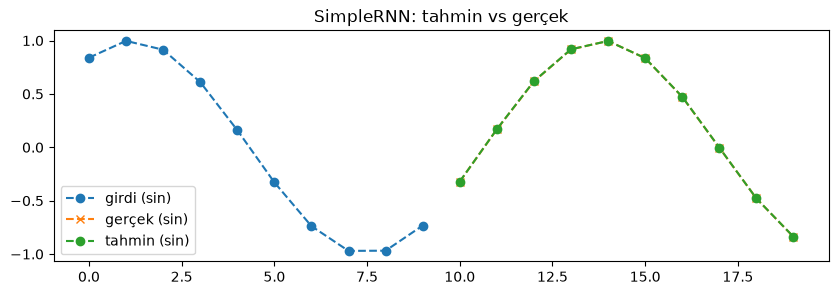

In [6]:
i = 0
pred = rnn.predict(X_val[i:i+1], verbose=0)[0]

plt.figure(figsize=(10, 3))
plt.plot(range(10), X_val[i, :, 0], 'o--', label='girdi (sin)')
plt.plot(range(10, 20), Y_val[i, :, 0], 'x--', label='gerçek (sin)')
plt.plot(range(10, 20), pred[:, 0], 'o--', label='tahmin (sin)')
plt.legend()
plt.title('SimpleRNN: tahmin vs gerçek')
plt.show()

In [7]:
rnn.save("../model/rnn_sine_wave.keras")